# Практическое задание №2

В файле **WIPO-GII_2022.xlsx** содержаться данные по странам о показателях, используемых для расчета Global Innovation Index за 2022 год. 

### В файле следующие переменные:																																
- Country
- Business environment
- Business sophistication index
- Citable documents H-index
- Creative goods and services
- Creative goods exports, % total trade
- Creative outputs index
- Cultural and creative services exports, % total trade
- Domestic market scale, bn PPP
- Ecological sustainability
- Expenditure on education, % GDP
- Firms offering formal training, %
- General infrastructure
- Government effectiveness
- Government's online service
- Graduates in science and engineering, %
- Gross expenditure on R&D, % GDP
- High-tech exports, % total trade
- High-tech imports, % total trade
- High-tech manufacturing, %
- Human capital and research index
- Information and Communications Technology access
- Information and Communications Technology services exports, % total trade
- Information and Communications Technology services imports, % total trade
- Information and Communications Technology use
- Infrastructure index
- Intangible assets
- Joint venture/strategic alliance deals/bn PPP GDP
- Knowledge absorption
- Knowledge and technology outputs index
- Knowledge workers
- Knowledge-intensive employment, %
- Logistics performance
- Market sophistication index
- Mobile app creation/bn PPP GDP
- Online creativity
- PISA scales in reading, maths and science
- Political and operational stability
- Political environment
- Pupil-teacher ratio, secondary
- QS university ranking average score of top 3 universities
- Research and development (R&D)
- Scientific and technical articles/bn PPP GDP
- Software spending, % GDP
- Tertiary education
- Tertiary enrolment, % gross
- University-industry R&D collaboration
- Region
- Region2
- Euro area
- European Union
- OECD members
- Least developed countries
- Income
- High income

In [ ]:
# %pip install jupyterlab pandas openpyxl matplotlib seaborn scipy matplotlib numpy kmodes

In [661]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from kmodes.kprototypes import KPrototypes
from scipy import stats


In [662]:
df_raw = pd.read_excel('data/WIPO-GII_2022.xlsx')
df = df_raw.filter(regex=r'^(?!.*_202[01]$)') # exclude 2020, 2021
df.columns = df.columns.str.replace(r'_2022|\$', '', regex=True) # rename variables: keep only 2022
df.shape

(139, 58)

In [663]:
# print(df.dtypes.to_string())
df.head(3).T

,0,1,2
Country,Cote d'Ivoire,Czechia,"Egypt, Arab Rep."
Business environment,48.3,42.1,45.0
Business sophistication index,21.8,46.2,20.4
Citable documents H-index,5.1,30.4,18.0
Creative goods and services,1.2,40.6,9.1
"Creative goods exports, % total trade",0.3,100.0,16.9
Creative outputs index,6.0,29.9,14.1
"Cultural and creative services exports, % total trade",2.1,15.3,0.0
"Domestic market scale, bn PPP",3.4,10.3,30.9
Ease of getting credit,NaN,NaN,NaN


In [664]:
# clear data
# useless_columns = df.isna().sum()
# useless_rows = df[df.isna().sum(axis=1) > (len(df.columns) / 2)]
# display(useless_columns)
# display(useless_rows)

df = df.dropna(axis=1, thresh=len(df) / 2)
df = df.dropna(axis=0, thresh=len(df.columns) / 2)

df.shape

(132, 56)

Выполните, пожалуйста, задания.

### 1. Проверка отличия распределения от «нормального»
Проанализируйте распределение значений любых пяти метрических переменных. Проведите тест для проверки того отличается ли распределение значений переменных от нормального распределения. Сформулируйте гипотезы и выводы по результатам анализа. Постройте гистограммы распределения с наложенной кривой нормального распределения. 

<h4 style="color: green">1. Решение</h4>

H0: расрпделение не отличается от нормального

H1: расрпделение не отличается от нормального. p-value > 0.05

<span style="color: red">NOTE:</span> проверяем только численные переменные с заполненными значениями

/var/folders/lw/jr3fj8rn4n3cvbgtlrmh3yr00000gn/T/ipykernel_37838/3501738005.py:24: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(d, fit=stats.norm)
/var/folders/lw/jr3fj8rn4n3cvbgtlrmh3yr00000gn/T/ipykernel_37838/3501738005.py:24: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(d, fit=stats.norm)


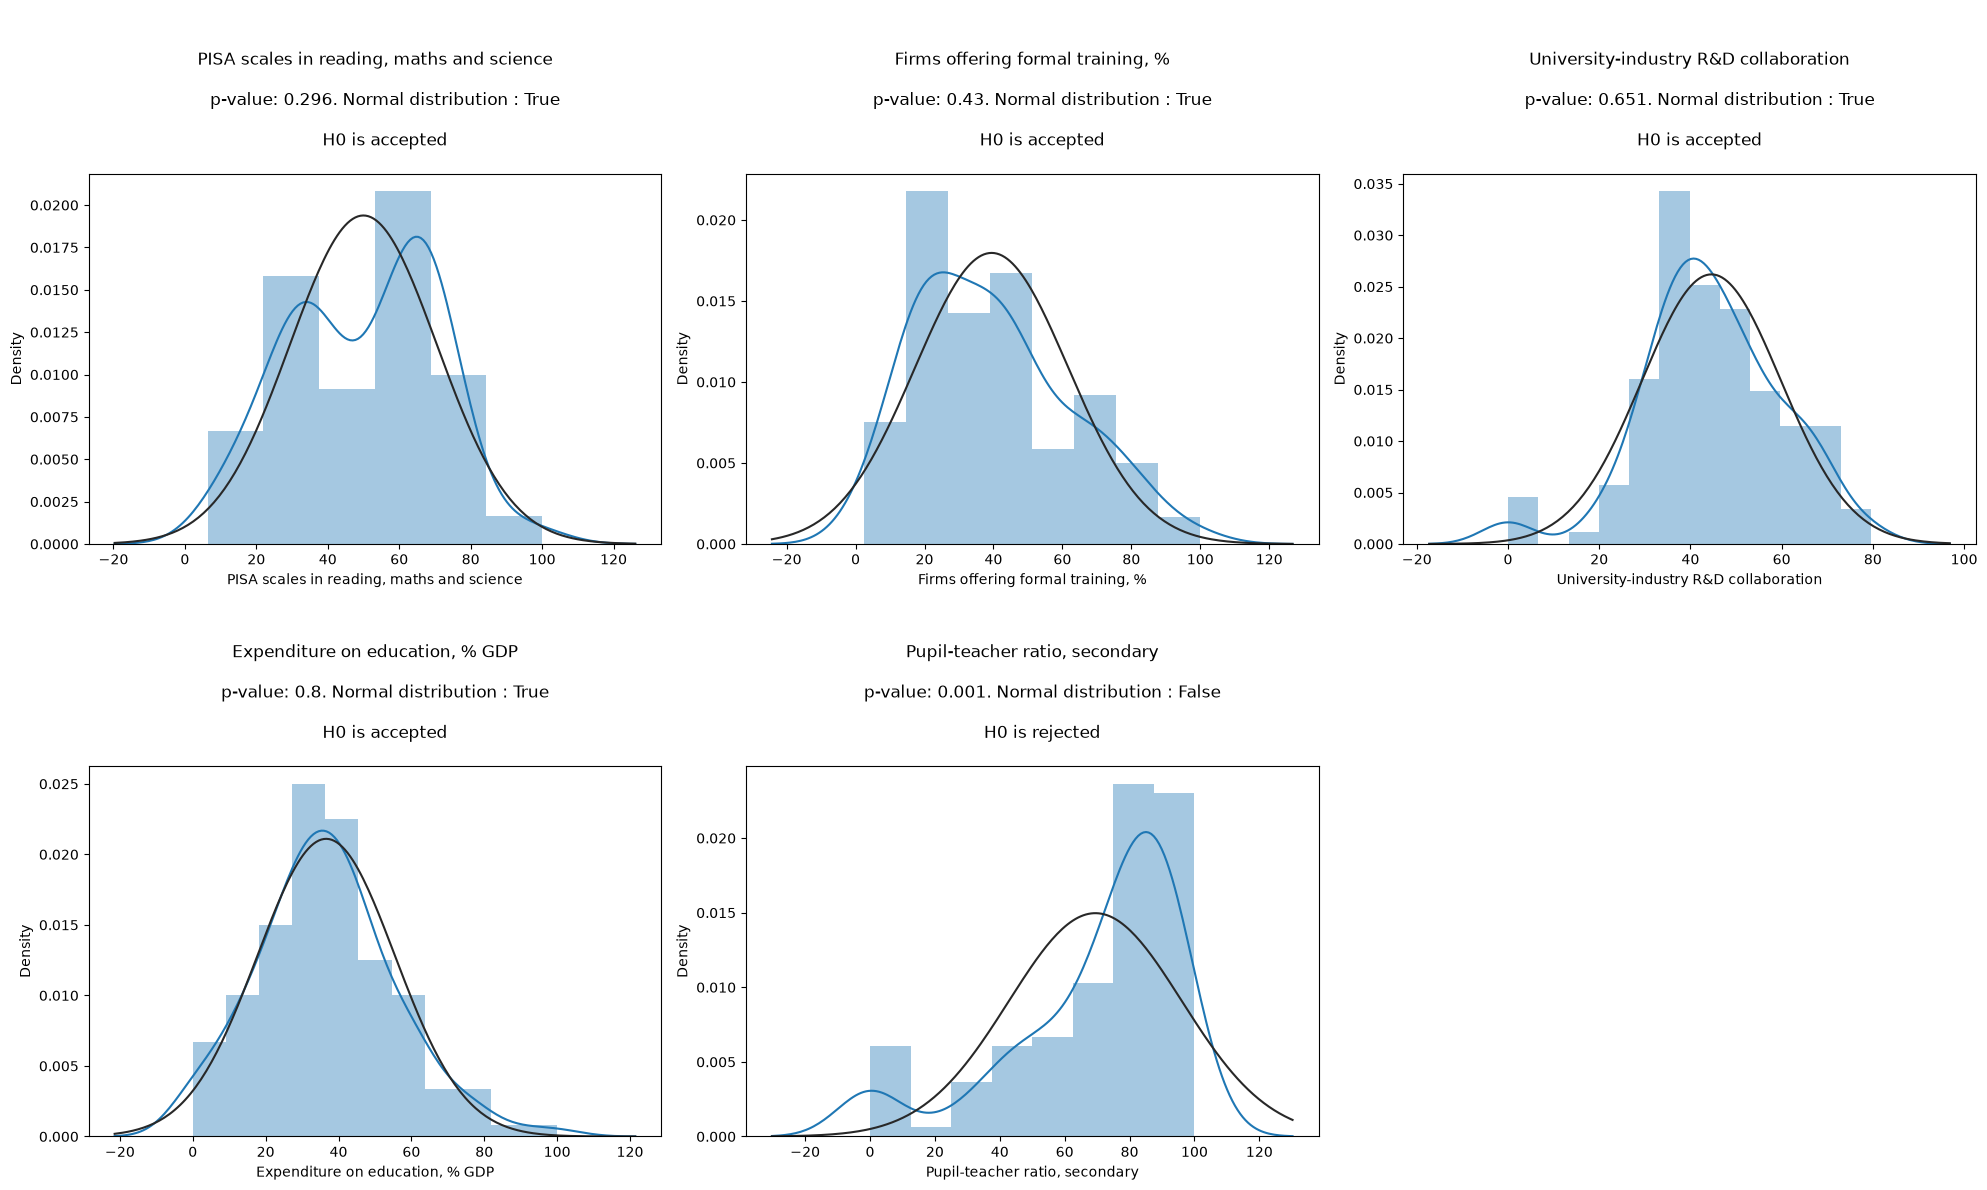

In [666]:
data = [df['PISA scales in reading, maths and science'],
        df['Firms offering formal training, %'],
        df['University-industry R&D collaboration'],
        df['Expenditure on education, % GDP'],
        df['Pupil-teacher ratio, secondary']
        ]

rows = math.ceil(len(data) / 3)
plt.figure(figsize=(20, 12))

for i, d in enumerate(data):
    d = d.dropna()

    # check share of 0 values in distribution
    zeros = (d == 0).sum()
    zero_percent = zeros / len(d) * 100
    if zero_percent > 25:
        d = d[d > 0]

    info = stats.kstest(d, stats.norm.cdf, args=(d.mean(), d.std()))
    is_normal = info.pvalue > 0.05

    plt.subplot(rows, 3, i + 1)
    sns.distplot(d, fit=stats.norm)

    plt.title(f'''
    \n{d.name}\n
    p-value: {round(info.pvalue, 3)}. Normal distribution : {is_normal}\n
    H0 is {'accepted' if is_normal else 'rejected'}
    ''')
plt.tight_layout()
plt.show()

### 2. Тест Хи-квадрат

Проведите тест Хи-квадрат не менее, чем с **двумя парами** переменных, для которых он **применим**. Можно использовать как исходные переменные, так и перекодировать их. Постройте для выбранных пар переменных таблицы сопряженности и прокомментируйте их. Сформулируйте гипотезы. Интерпретируйте результаты анализа. Обоснуйте свои выводы. Визуализируйте наблюдаемые тенденции на подходящих графиках.


<h4 style="color: green">2. Решение</h4>

H0: переменная `Region2` не связана с переменной `High income`. 

H1: переменная `Region2` влияет на переменную `High income`. Например у стран из региона Europe значений High income будет чаще True, у стран Африки False

In [667]:
income_high = pd.crosstab(
  df['Region2'],
  df['High income']
  )

display(income_high)
res = stats.chi2_contingency(income_high)
res

High income,0,1
Region2,,
Americas,14,6
Asia-Pacific,19,7
Europe,14,31
Middle East and North Africa,7,7
Sub-Saharan Africa,27,0


Chi2ContingencyResult(statistic=np.float64(37.267474815187235), pvalue=np.float64(1.5866226318815698e-07), dof=4, expected_freq=array([[12.27272727,  7.72727273],
       [15.95454545, 10.04545455],
       [27.61363636, 17.38636364],
       [ 8.59090909,  5.40909091],
       [16.56818182, 10.43181818]]))

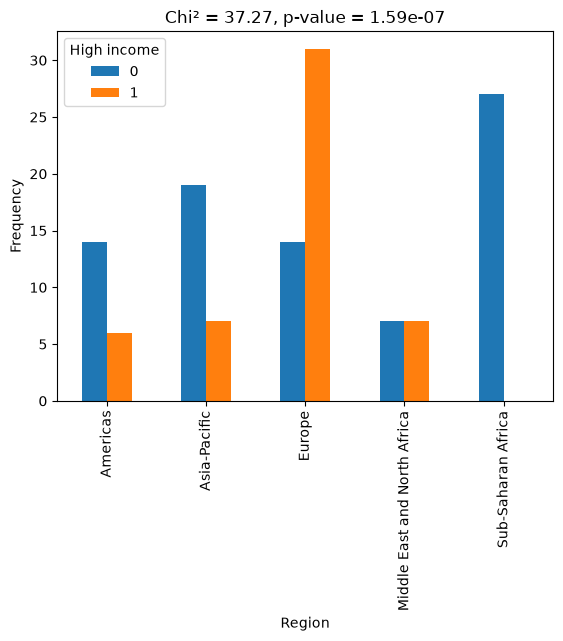

In [668]:
income_high.plot(kind='bar')
plt.xlabel('Region')
plt.ylabel('Frequency')
plt.legend(title='High income')
plt.title(f'Chi² = {res.statistic:.2f}, p-value = {res.pvalue:.3g}')
plt.show()

<span style='color: green'>Вывод:</span> 

p-value < 0.05, поэтому H0 отвергается. Между `Region2` и `High income` есть связь. Например в Европе доля стран с высоким доходом выше, а в некоторых регионаз Африки нет стран с высоким доходом.

H0: переменная `European Union` не связана с переменной `OECD members`. 

H1: переменная `European Union` влияет на переменную `OECD members`. Например среди стран ЕС будет больше доля членов OECD

In [669]:
eu_oecd = pd.crosstab(
  df['European Union'],
  df['OECD members']
  )

display(eu_oecd)
res = stats.chi2_contingency(eu_oecd)

OECD members,0,1
European Union,,
0,89,16
1,5,22


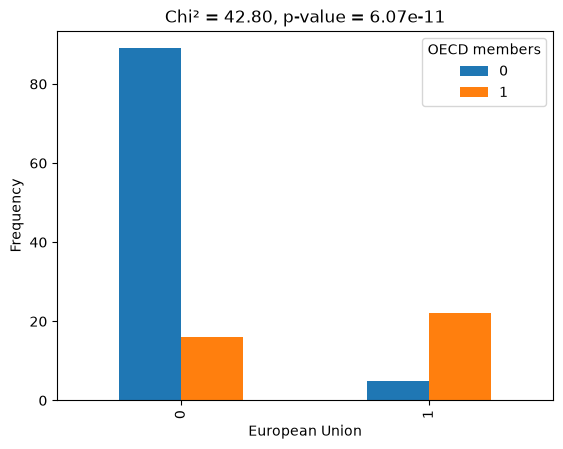

In [670]:
eu_oecd.plot(kind='bar')
plt.xlabel('European Union')
plt.ylabel('Frequency')
plt.legend(title='OECD members')
plt.title(f'Chi² = {res.statistic:.2f}, p-value = {res.pvalue:.3g}')
plt.show()

<span style='color: green'>Вывод:</span>


p-value < 0.05, поэтому H0 отвергается. Между `European Union` и `OECD members` есть связь. Например большинство участников OECD имеют членство ЕС.

### 3. Парная корреляция

Проведите корреляционный анализ переменных (нужно рассмотреть не менее **трёх разных пар** переменных). Обоснуйте выбор рассчитываемых коэффициентов корреляции. Сформулируйте гипотезы. Визуализируйте наблюдаемые тенденции на подходящих графиках. Интерпретируйте результаты анализа (статистическая значимость, сила и направление взаимосвязи). Заполните таблицу (не менее 3 записей). 	 	 	 	 

| Анализируемые пары переменных | Выбранный коэффициент корреляции (обоснование выбора) | Гипотезы | Сила взаимосвязи | Направление взаимосвязи | Статистическая значимость взаимосвязи |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |
| --- | --- | --- | --- | --- | --- |

<h4 style="color: green">3.1. Решение</h4>

H0: переменная `Firms offering formal training` не связана с переменной `University-industry R&D collaboration`. 

H1: переменная `Firms offering formal training` взаимосвязана с `University-industry R&D collaboration`. При более активном участии ВУЗов в R&D повышается количество рабочих мест со стажировками

PearsonRResult(statistic=np.float64(0.12333537081030402), pvalue=np.float64(0.23629069926033025))

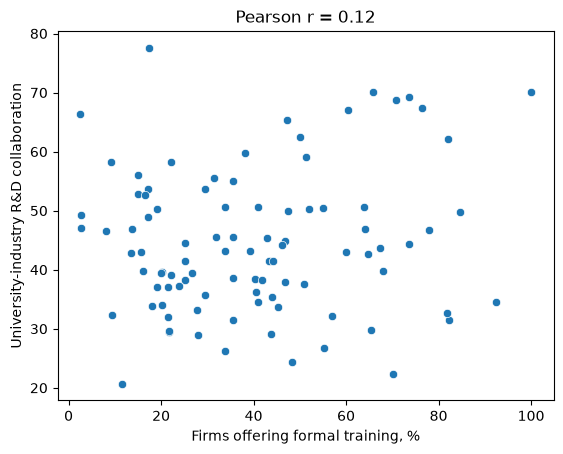

In [671]:
# Pearson Correlation
firms = 'Firms offering formal training, %'
rd = 'University-industry R&D collaboration'
f_r = df[(df[firms] > 0) & (df[rd] > 0)][[firms, rd]]
firms_rd = stats.pearsonr(f_r[firms], f_r[rd])
display(firms_rd)

sns.scatterplot(data=f_r, x=firms, y=rd)
plt.title(f'Pearson r = {firms_rd.statistic:.2f}')
plt.show()

<span style='color: green'>Вывод:</span>


Коэффициент корреляции Пирсона r = 0.12 (r< 0.5) - очень слабая положительная связь, поэтому H0 принимается. На scatter plot визуально не выявляется линейная взиамосвязь. Связь участия ВУЗов в R&D и количества рабочих мест со стажировками не выявлена.

<h4 style="color: green">3.2. Решение</h4>

H0: переменная `Income` не влияет на переменную `Creative outputs index`. 

H1: переменная `Income` влияет на `Creative outputs index`. При более высоком уровне дохода увеличивается креативный сектор

SignificanceResult(statistic=np.float64(0.6740428501701505), pvalue=np.float64(8.162800724245817e-19))


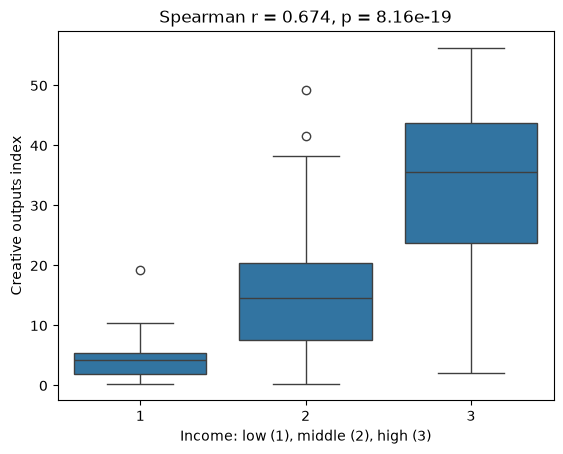

In [672]:
# Spearman Correlation
income = df['Income'].map({
    'low income': 1,
    'middle income': 2,
    'high income': 3
})

creative_income = stats.spearmanr(df['Creative outputs index'], income, nan_policy='omit')
print(creative_income)

sns.boxplot(
    x=income,
    y=df['Creative outputs index'],
    order=[1, 2, 3]
)

plt.xlabel('Income: low (1), middle (2), high (3)')
plt.ylabel('Creative outputs index')
plt.title(f'Spearman r = {creative_income.statistic:.3f}, p = {creative_income.pvalue:.3g}')
plt.show()

<span style='color: green'>Вывод:</span>


Коэффициент корреляции Спирмана 0.67 (r > 0.5) - положительная средняя корреляция, поэтому есть основания отвергнуть H0. На boxplot видно как медиана количества креативных метрик значительно увеличивается при повышении уровня дохода

<h4 style="color: green">3.3. Решение</h4>

H0: переменная `High income` не влияет на переменную `Ecological sustainability`. 

H1: переменная `High income`  влияет на переменную `Ecological sustainability`.  При более высоком уровне дохода также наблюдается высокий уровень экологической устойчивости.

SignificanceResult(statistic=np.float64(0.5477755894425986), pvalue=np.float64(1.064616575826253e-11))


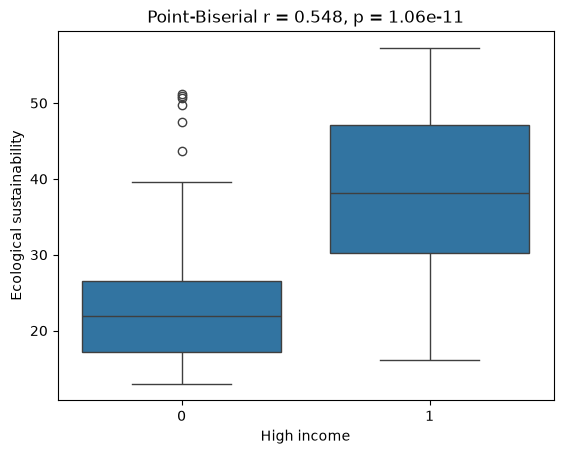

In [673]:
# Point-Biserial Correlation
eco_income = stats.pointbiserialr(df['Ecological sustainability'], df['High income'])
print(eco_income)

sns.boxplot(data=df, x='High income', y='Ecological sustainability')
plt.title(f'Point-Biserial r = {eco_income.statistic:.3f}, p = {eco_income.pvalue:.3g}')
plt.show()

<span style='color: green'>Вывод:</span>


Коэффициент точечно-бисериальной корреляции 0.55 (0.5 < r < 0.7) - положительная средняя корреляция, поэтому есть основания отвергнуть H0. На boxplot видно как медиана экологической устойчивости значительно увеличивается при повышении уровня дохода

<span style='color: green'>ВЫВОДЫ 3.1-3.3:</span>

In [674]:
results = pd.DataFrame([
    [
        'Firms offering formal training × University-industry R&D collaboration',
        'Pearson (two numerical variables)',
        'H0: ρ = 0; H1: ρ != 0',
        f'Weak, r = {firms_rd.statistic:.3f}',
        'Positive',
        f'Not significant, p-value = {firms_rd.pvalue:.3g}'
    ],
    [
        'Creative outputs index × Income',
        'Spearman (numerical + ordinal)',
        'H0: ρ = 0; H1: ρ != 0',
        f'Medium, r = {creative_income.statistic:.3f}',
        'Positive',
        f'Significant, p-value = {creative_income.pvalue:.3g}'
    ],
    [
        'Ecological sustainability × High income',
        'Point-biserial (numerical + binary)',
        'H0: ρ = 0; H1: ρ != 0',
        f'Medium, r = {eco_income.statistic:.3f}',
        'Positive',
        f'Significant, p-value = {eco_income.pvalue:.3g}'
    ]
], columns=[
    'Анализируемые пары переменных',
    'Выбранный коэффициент корреляции (обоснование выбора)',
    'Гипотезы',
    'Сила взаимосвязи',
    'Направление взаимосвязи',
    'Статистическая значимость взаимосвязи'
])

display(results)

,Анализируемые пары переменных,Выбранный коэффициент корреляции (обоснование выбора),Гипотезы,Сила взаимосвязи,Направление взаимосвязи,Статистическая значимость взаимосвязи
0,Firms offering formal training × University-in...,Pearson (two numerical variables),H0: ρ = 0; H1: ρ != 0,"Weak, r = 0.123",Positive,"Not significant, p-value = 0.236"
1,Creative outputs index × Income,Spearman (numerical + ordinal),H0: ρ = 0; H1: ρ != 0,"Medium, r = 0.674",Positive,"Significant, p-value = 8.16e-19"
2,Ecological sustainability × High income,Point-biserial (numerical + binary),H0: ρ = 0; H1: ρ != 0,"Medium, r = 0.548",Positive,"Significant, p-value = 1.06e-11"


### 4. Кластерный анализ данных

4.1. Выберите не менее 5 интересующих Вас метрических переменных для последующего проведения кластерного анализа данных. Приведите аргументы в пользу того, что они могут быть использованы для кластеризации объектов наблюдения.

4.2. Выберите подходящий алгоритм кластеризации и обоснуйте свой выбор. Определите число кластеров, объясните своё решение. Опишите получившиеся кластеры с помощью описательной статистки. Нужно не просто рассчитать статистики в таблицах, но детально описать полученные результаты. Дайте названия кластерам и обоснуйте их.

<h4 style="color: green">4.1 - 4.2. Решение</h4>

H0: Выбранные переменные не позволяют выделить логичные группы стран

H1: Переменные
- PISA scales in reading, maths and science (числовая)
- Ecological sustainability
- Expenditure on education, % GDP (числовая)
- Income (категориальная/ординальная)
- Creative outputs index (числовая)
- High-tech exports, % total trade (числовая)

могут объединиться по группам стран, различающиеся по уровню социально-экономического и технологического развития. Предполагаем из теортетических представлений (~~где то слышала~~), что объекты могут объединяться по показателям "не первой необходимости": грамотности, технологий, развития креативного сектора и экологии.

<span style="color: red">NOTE:</span> анализ будет проводиться для объектов с заполненными значениями раасматриваемых переменных: объекты с значениями 0 числовых переменных будут удалены

- Выбор алгоритма

Так как для кластеризации выбраны 5 чиловых переменных и 1 категориальная (ординальная) можно выбрать алгоритм  **k-prototypes**, тк он сочетает подходы работы с числовыми переменными (как k-means) и категориальными (как k-modes). 

- Стандартизация

Нужно стаднартизировать числовые переменные (выберем z-score standartization). Категориальную переменную `Income` перекодировать не требуется для алгоритма `k-prototypes`, но требуется для проверки корреляции с другими переменными

- Определение количества кластеров

Так как алгоритмы k-семейства требуют определения количества кластеров, можно воспользоваться методом локтя.

In [675]:
# choose objects
cols = [
    'Ecological sustainability',
    'Expenditure on education, % GDP',
    'Creative outputs index',
    'High-tech exports, % total trade',
    'PISA scales in reading, maths and science'
]

X = df[cols + ['Income']].copy()

for col in cols:
    zeros = (X[col] == 0).sum()
    total = X[col].count()
    zero_percent = zeros / total * 100

    if zero_percent > 30:
        X[col] = X[col].replace(0, np.nan)

X = X.dropna()
print('Countries remaining:', len(X))

Countries remaining: 77


In [676]:
# check multicollinearity
# numeric variables
display(X[cols].corr())

,Ecological sustainability,"Expenditure on education, % GDP",Creative outputs index,"High-tech exports, % total trade","PISA scales in reading, maths and science"
Ecological sustainability,1.000000,-0.179786,0.383602,0.128516,0.332156
"Expenditure on education, % GDP",-0.179786,1.000000,0.289839,-0.064431,0.122484
Creative outputs index,0.383602,0.289839,1.000000,0.377400,0.706300
"High-tech exports, % total trade",0.128516,-0.064431,0.377400,1.000000,0.422347
"PISA scales in reading, maths and science",0.332156,0.122484,0.706300,0.422347,1.000000


In [677]:
# categorial (ordinal) variable
income = X['Income'].map({
    'low income': 1,
    'middle income': 2,
    'high income': 3
})

for col in cols:
    r, p = stats.spearmanr(X[col], income)
    print(f'Income x {col}')
    print(f'Spearman r: {r:.3f}, p-value: {p:.3g}\n')

Income x Ecological sustainability
Spearman r: 0.362, p-value: 0.0012

Income x Expenditure on education, % GDP
Spearman r: 0.250, p-value: 0.0286

Income x Creative outputs index
Spearman r: 0.515, p-value: 1.66e-06

Income x High-tech exports, % total trade
Spearman r: 0.233, p-value: 0.0411

Income x PISA scales in reading, maths and science
Spearman r: 0.613, p-value: 3.2e-09



- Вывод о выборе переменных:

Обращает на себя внимание коэффициент корреляции Спирмена `r = 0.7` переменных `Creative outputs index` и `PISA scales in reading, maths and science`. Это предельный уровень корреляции для кластерного анализа, но все еще допустимый.  Несмотря на достаточно сильную связь, переменные характеризуют разные аспекты развития стран, поэтому решено оставить все переменные


In [678]:
# z-score standartization
X_original = X.copy()
X[cols] = stats.zscore(X[cols])

display(X.head(3))

,Ecological sustainability,"Expenditure on education, % GDP",Creative outputs index,"High-tech exports, % total trade","PISA scales in reading, maths and science",Income
1,0.999100,-0.242626,0.017187,1.603891,0.774539,high income
3,1.770894,-0.148598,1.683993,-1.700721,1.474351,high income
5,-0.758875,-0.107461,1.819913,1.801181,1.255660,high income


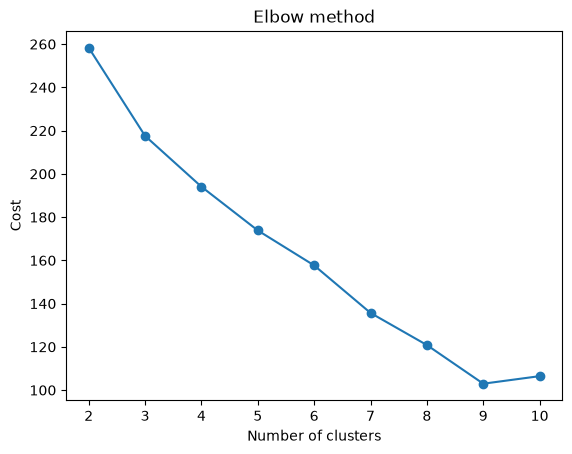

In [679]:
# amount of clusters

costs = []
clusters = range(2, 11)

for k in clusters:
    kproto = KPrototypes(n_clusters=k, random_state=1, n_init=3)
    kproto.fit_predict(X.to_numpy(), categorical=[5])
    costs.append(kproto.cost_)

plt.plot(clusters, costs, marker='o')
plt.title('Elbow method')
plt.xlabel('Number of clusters')
plt.ylabel('Cost')
plt.xticks(clusters)
plt.show()

- Вывод о количестве кластеров

График локтя явно показывает замедление изменения качества кластеризации только на 9 клаестерах. Так как выборка небольшая (после очистки осталось 77 стран), поэтому разделение на 9 групп приведёт к слишком мелким кластерам. Выберем 3 кластера, чтобы выделить основные различия между странами и сохранить интерпретируемость результатов

In [698]:
kproto_model = KPrototypes(n_clusters=3, random_state=1, n_init=3)

X['Cluster'] = kproto_model.fit_predict(
    X.to_numpy(),
    categorical=[5]
)
X.head()

,Ecological sustainability,"Expenditure on education, % GDP",Creative outputs index,"High-tech exports, % total trade","PISA scales in reading, maths and science",Income,Cluster
1,0.999100,-0.242626,0.017187,1.603891,0.774539,high income,1
3,1.770894,-0.148598,1.683993,-1.700721,1.474351,high income,1
5,-0.758875,-0.107461,1.819913,1.801181,1.255660,high income,1
9,-1.676452,0.045335,-0.311881,-0.673167,0.492670,high income,2
10,1.256365,-0.454189,-0.769716,0.617439,0.254540,high income,0


In [699]:
means = X.groupby('Cluster')[['Ecological sustainability', 'Expenditure on education, % GDP', 'Creative outputs index', 'High-tech exports, % total trade', 'PISA scales in reading, maths and science', 'Income' ]].mean(numeric_only=True)

means

,Ecological sustainability,"Expenditure on education, % GDP",Creative outputs index,"High-tech exports, % total trade","PISA scales in reading, maths and science"
Cluster,,,,,
0,0.213490,-1.015093,-0.687052,0.195229,-0.820556
1,0.389141,0.244994,0.779329,0.382209,0.823885
2,-0.950966,0.435845,-0.901344,-0.921013,-0.868075


In [700]:
X['Cluster'].value_counts().sort_index()

Cluster
0    18
1    39
2    20
Name: count, dtype: int64

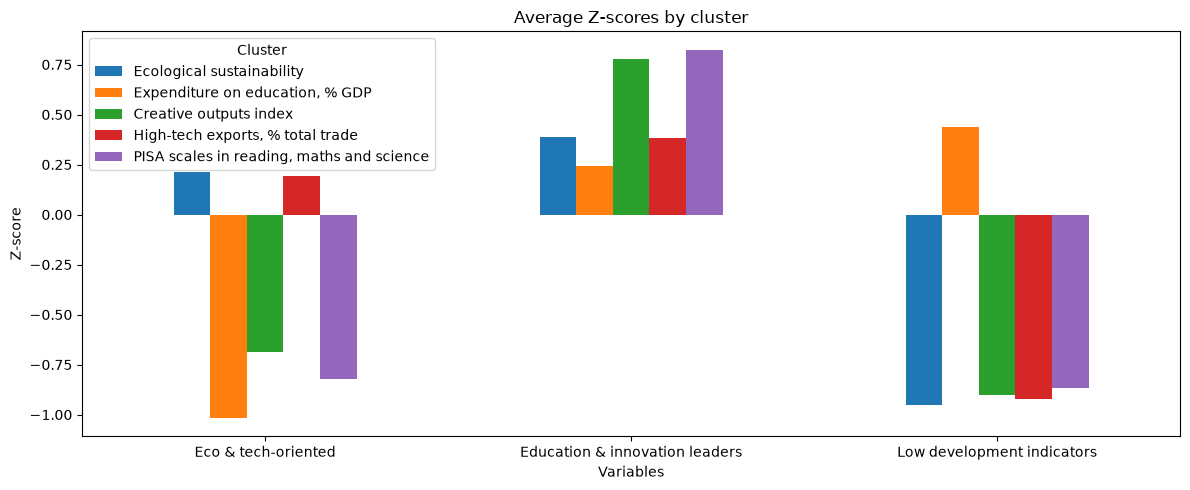

In [701]:
means = X.groupby('Cluster')[cols].mean()
means.index = means.index.map({
    0: 'Eco & tech-oriented',
    1: 'Education & innovation leaders',
    2: 'Low development indicators'
})

means.plot(kind='bar', figsize=(12, 5))

plt.title('Average Z-scores by cluster')
plt.xlabel('Variables')
plt.ylabel('Z-score')
plt.xticks(rotation=360)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

<span style='color: green'>Вывод 4.1 - 4.2.</span>

Кластеризация методом k-prototypes позволила выделить 3 группы стран:

- Кластер 0: Выше среднего экологическая устойчивость и высокотехнологичный экспорт
- Кластер 1: Наиболее высокие показатели базовой грамотности PISA и креативного сектора. остальные показатели тоже выше среднего
- Кластер 2: практически все показатели значительно ниже показателей лидеров. Также траты довольно высокие, но остальные показатели остаются значительно ниже среднего

Полученные результаты согласуются с H1: выбранные характеристики позволяют выделить три интерпретируемые группы стран.

4.3. Проведите апостериорный анализ данных на основе категориальных переменных датасета. Например, рассмотрите как распределены страны разных регионов по кластерам или в какие кластеры в основном попали страны-члены ОЭСР?

Cluster,0,1,2
Region,,,
East Asia & Pacific,30.769231,61.538462,7.692308
Europe & Central Asia,23.255814,62.790698,13.953488
Latin America & Caribbean,20.000000,0.000000,80.000000
Middle East & North Africa,22.222222,22.222222,55.555556
North America,0.000000,100.000000,0.000000


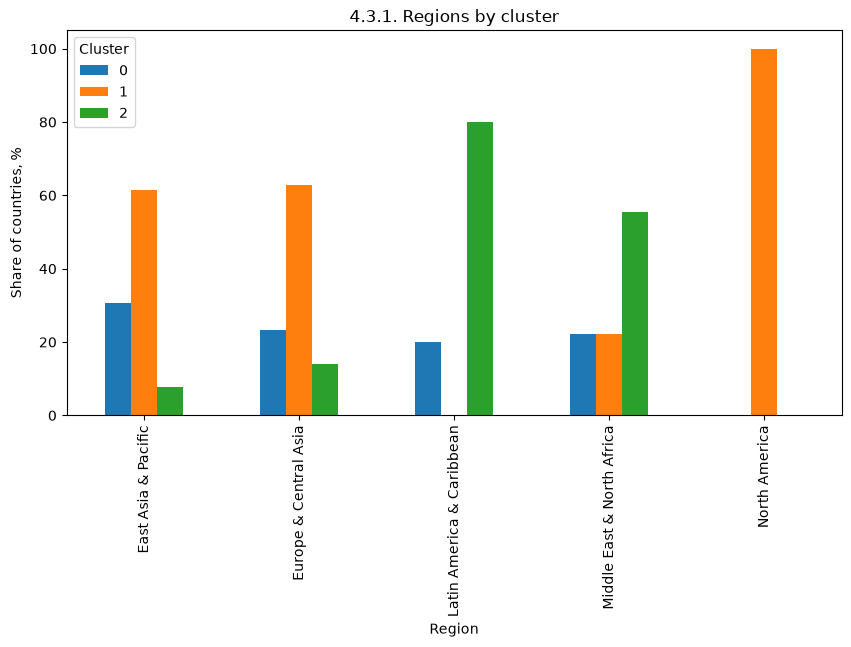

In [702]:
regions = pd.crosstab(df.loc[X.index, 'Region'], X['Cluster'], normalize='index') * 100

display(regions)

regions.plot(kind='bar', figsize=(10, 5))
plt.title('4.3.1. Regions by cluster')
plt.xlabel('Region')
plt.ylabel('Share of countries, %')
plt.show()

Cluster,0,1,2
OECD members,,,
0,38.461538,17.948718,43.589744
1,7.894737,84.210526,7.894737


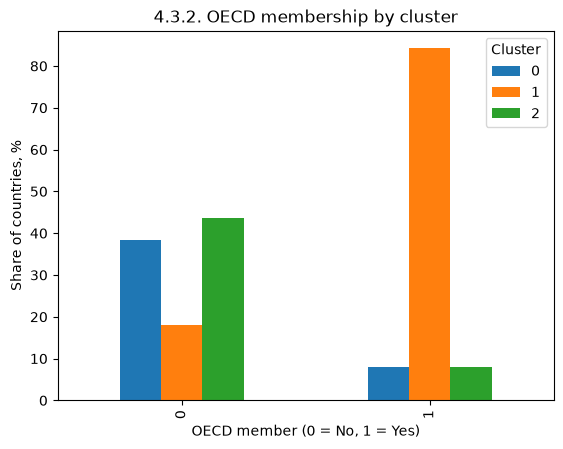

In [704]:
oecd = pd.crosstab(df.loc[X.index, 'OECD members'], X['Cluster'], normalize='index') * 100

display(oecd)

oecd.plot(kind='bar')
plt.title('4.3.2. OECD membership by cluster')
plt.xlabel('OECD member (0 = No, 1 = Yes)')
plt.ylabel('Share of countries, %')
plt.show()

4.4. Почему получилась именно такая кластерная структура? Полученные результаты соответствуют вашем изначальным предположениям или оказались неожиданными?

<span style='color: green'>Вывод 4.3.</span>

- На графике 4.3.1 видно, что Северная Америка (США и Канада): 100% стран в кластере 1 (лидеры)
- Латинская Америка и Карибский бассейн: ок. 80% в кластере 2 (слабо развитые) и 0% в кластере 1 (лидеры)
- На графике 4.3.2. видно, что среди стран OECD ок. 85% относятся к кластеру 1, а среди остальных стран ок. 15%.

### Комментарии к заданию и принципам его оценивания:

 - Все пункты задания должны сопровождаться _выполненным_ фрагментом кода.
 - Если Вы получили результаты в виде статистических показателей, таблиц или графиков, при этом никак их не прокомментировали и не сформулировали содержательные выводы на их основе, то работа оценивается в 0 баллов, в этом случае анализ данных не проведён.
 - Если Вы полностью выполнили это задание, то получаете за него 8 баллов (отлично). Для получения более высокой оценки нужно выйти за рамки предложенного задания. В случае с текущим заданием это может быть дополнительное самостоятельное изучение других алгоритмов кластеризации и их применение для анализа данных, или развернутое и глубокое исследование имеющихся данных на основе применения всех пройденных на занятиях алгоритмов кластеризации, сравнение результатов и выбор лучшей кластерной модели с объяснением своего выбора.
 - В этом задании четыре пункта. Первый весит 15%, второй - 15%, третий - 15%, четвертый - 55%.

### Этот файл нужно сохранить как Jupyter Notebook (.ipynb) и отправить на amelikyan@hse.ru до 23:55 22 октября.